# Image Classification with PyTorch: Image Data Augmentation

[Pablo Carballeira] (http://dymas.ii.uam.es/webvpu/gti/user/186/), Escuela Politecnica Superior, Universidad Autónoma de Madrid.

Parts of this code have been adapted from then work of Kevin McGuinness (http://www.eeng.dcu.ie/~mcguinne/), School of Electronic Engineering, Dublin City University, Ben Trevett (https://github.com/bentrevett), Heriot-Watt University, and Dhruvil Karani (https://github.com/DhruvilKarani)

You can find documentation about working in Colab here (https://colab.research.google.com/notebooks/intro.ipynb)

----
In this lab assignment, you will observe the effect of different common image data augmentation techniques. In the next part of the assignment (using a different notebook), you will evaluate if these techniques can improve the learning process of a network



# Instructions

Anywhere you see a **???** in the code below, fill in in with the correct code.

# Import packages


Find the PyTorch docs at https://pytorch.org/docs/stable/index.html

Tutorials: https://pytorch.org/tutorials/

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn.metrics as metrics
from sklearn import decomposition
from sklearn import manifold

import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision.datasets.utils import download_file_from_google_drive
import torchvision.datasets as datasets
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import PIL
from PIL import Image
from torchvision.datasets import CIFAR10

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

import sys
import os
import copy
import random
import time

import seaborn as sns
from collections import Counter

# sys.path.append("../models")
# from models.resnet import ResNet

from torch.autograd import Variable
import seaborn as sns


# Enable GPU acceleration

Open to the Edit menu and select *Notebook settings* and check that *GPU* is selected under hardware accelerator.


In [2]:
# make sure to enable GPU acceleration!
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


We set the random seed so all of our experiments can be reproduced.

In [3]:
SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# Image augmentation techniques on CIFAR10: examples

Here we will observe the effect of applying different transformations to the images of the CIFAR10 dataset an see the results in some sample images

## Example of transformation definition

Here we show the effect of applying horizontal flipping and random cropping (two transforms that we have used in the previous lab session). Here,  `RandomHorizontalFlip` flips the image horizontally with a probability of `0.5`. `RandomCrop` is used to padd the image with 4 pixels all around the image, and then take a random crop of 32x32 pixels. Note that the way to apply `RandomCrop` is slightly different to the previous sccript (resizing + cropping)  

In [4]:
example_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])
])

## Load the dataset applying the transformation


In [5]:
# Download CIFAR10 from Google Drive link to avoid bandwith problems in official server
# Install gdown
!pip -q install gdown
# Create destination folder
!mkdir -p data

# Download using the Google Drive file ID
!gdown --id 1Kg6Hl3hJt75hUMF4XsOPxgAWdcWqIBIB -O data/cifar-10-python.zip
!unzip -o data/cifar-10-python.zip -d data/CIFAR10

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1Kg6Hl3hJt75hUMF4XsOPxgAWdcWqIBIB
From (redirected): https://drive.google.com/uc?id=1Kg6Hl3hJt75hUMF4XsOPxgAWdcWqIBIB&confirm=t&uuid=7a9c30d9-3c54-47dc-a9fb-9889a8939184
To: /content/data/cifar-10-python.zip
100% 167M/167M [00:03<00:00, 52.3MB/s]
Archive:  data/cifar-10-python.zip
   creating: data/CIFAR10/cifar-10-python/
   creating: data/CIFAR10/cifar-10-python/cifar-10-batches-py/
  inflating: data/CIFAR10/cifar-10-python/cifar-10-batches-py/batches.meta  
  inflating: data/CIFAR10/cifar-10-python/cifar-10-batches-py/data_batch_1  
  inflating: data/CIFAR10/cifar-10-python/cifar-10-batches-py/data_batch_2  
  inflating: data/CIFAR10/cifar-10-python/cifar-10-batches-py/data_batch_3  
  inflating: data/CI

In [6]:
# labels of the CIFAR10 dataset
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Loading dataset from the local 'data/CIFAR10' folder without downloading
cifar10_valid = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download=False, transform=example_transform)

In [7]:
print(f'train set is', ' x '.join(str(x) for x in cifar10_valid.data.shape))


train set is 10000 x 32 x 32 x 3


## Let us show some of the modified training images.


Auxiliary functions to show a set of transformed images and their labels

In [8]:
def normalize_image(image):
    image_min = image.min()
    image_max = image.max()
    image.clamp_(min = image_min, max = image_max)
    image.add_(-image_min).div_(image_max - image_min + 1e-5)
    return image

In [9]:
def plot_images(images, labels, classes):

    n_images = len(images)

    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))

    fig = plt.figure(figsize = (8, 8))

    for i in range(rows*cols):

        ax = fig.add_subplot(rows, cols, i+1)

        image = images[i]
        image = normalize_image(image)

        ax.imshow(image.permute(1, 2, 0).cpu().numpy())
        ax.set_title(classes[labels[i]])
        ax.axis('off')

Let's show a set of images. By running the following cell several times, you can check that several exexutions of the code will produce different transformations. Transformations are applied with a given probbilty each time the CIFAR10 class is called.

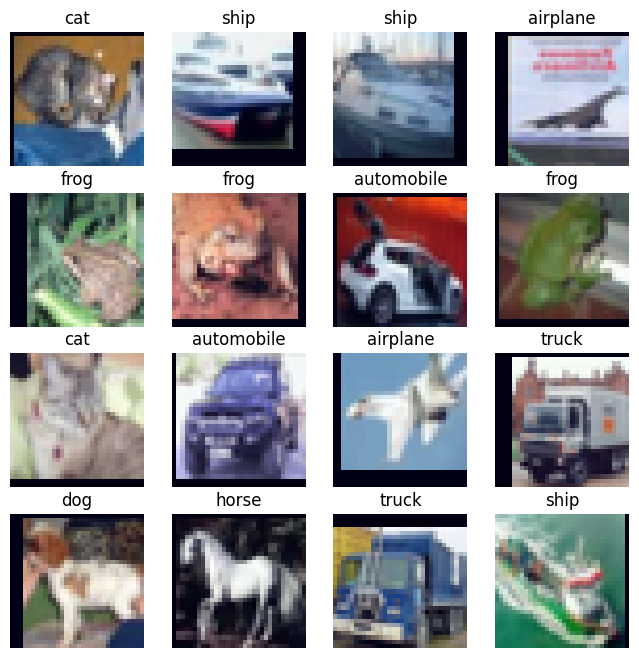

In [10]:
N_IMAGES = 16

images, labels = zip(*[(image, label) for image, label in
                           [cifar10_valid[i] for i in range(N_IMAGES)]])
classes = cifar10_valid.classes
plot_images(images, labels, classes)

## Rotation


In [11]:
# define a transformation to rotate the images a random angle, betwen -30 and 30 degrees.
# Use the bilinear interpolation for image resampling
valid_transform = transforms.Compose([
    transforms.RandomRotation([-30, 30], interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])

])

cifar10_valid = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download = False, transform=valid_transform)

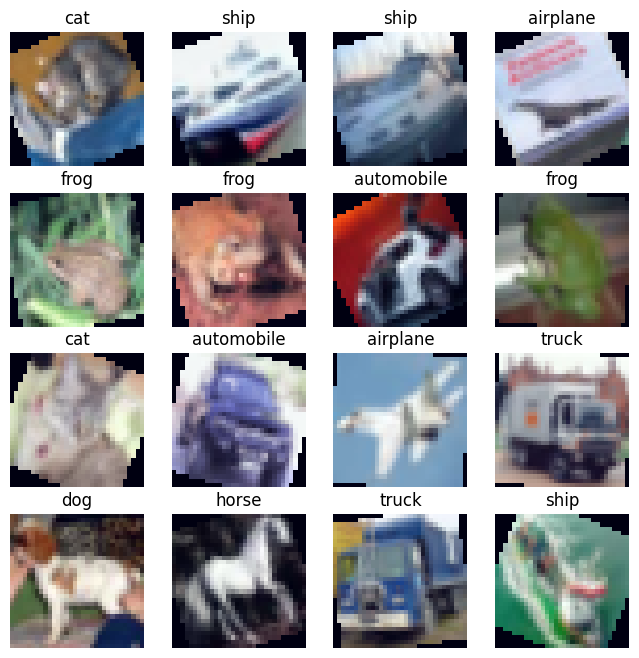

In [12]:
N_IMAGES = 16

images, labels = zip(*[(image, label) for image, label in
                           [cifar10_valid[i] for i in range(N_IMAGES)]])
classes = cifar10_valid.classes
plot_images(images, labels, classes)

## Random Erasing

In [13]:
# define the transformation to erase a random square patch of all images,
# and replace it with a mid-gray patch. The erased patch must be between 2% and 25% of the image size
valid_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.RandomErasing(p=1,                           # todas las imágenes
                             scale=(0.02, 0.25),            # escala de entre el 2% y el 25% de cada imagen
                             value=0.5,                     # deduzco que esto será gris en escala de 0 a 1
                             ratio=(1, 1)),                 # para que sea un cuadrado

    transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])

])

cifar10_valid = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download = False, transform=valid_transform)

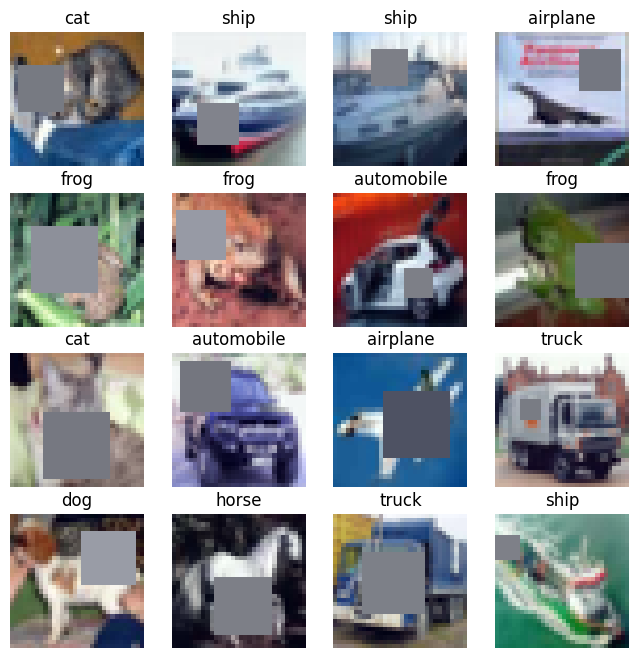

In [14]:
N_IMAGES = 16

images, labels = zip(*[(image, label) for image, label in
                           [cifar10_valid[i] for i in range(N_IMAGES)]])
classes = cifar10_valid.classes
plot_images(images, labels, classes)

## Color Jitter

In [15]:
# define the transformation to apply color jitter to all images. The parameters of the transformation are:
# brightness=0.3, contrast=0.3, saturation=0.2, hue=0.2
valid_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])
])

cifar10_valid = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download = False, transform=valid_transform)

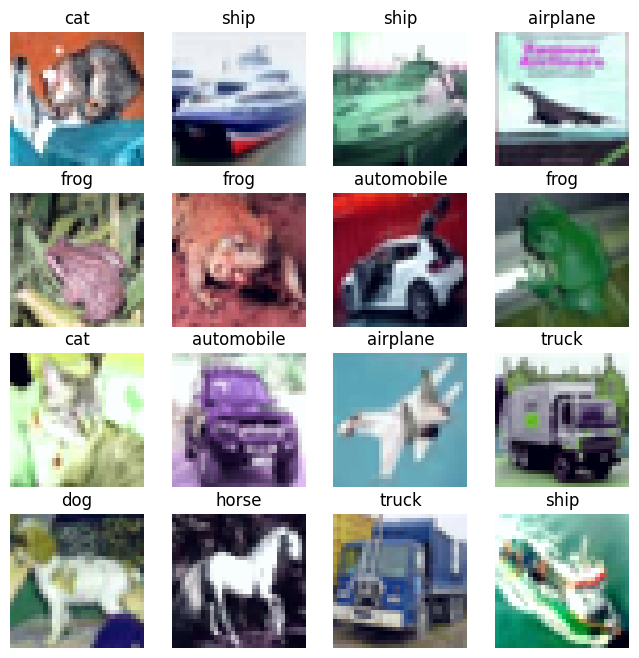

In [16]:
N_IMAGES = 16

images, labels = zip(*[(image, label) for image, label in
                           [cifar10_valid[i] for i in range(N_IMAGES)]])
classes = cifar10_valid.classes
plot_images(images, labels, classes)

## Five Crops at test time

We will also try an image transformation that is used at inference time.  Instead of obtaining class scores from a single test image, class scores can be averaged over the scores obtained drom slightly different inputs (image crops)


In [17]:

# Resize the input image to 40x40 pixels (using bilinear interpolation) and use the FiveCrop function to extract
# five crops from the resized image. Warning: Each input image generates 5 images. Therefore you have to change
# the way to convert images to Tensors, and the normalization.

# Check the FiveCrop help to learn how to do it

norm = transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])
test_crops_transform = transforms.Compose([
    transforms.Resize(40),
    transforms.FiveCrop(32),
    transforms.Lambda(lambda crops: torch.stack([norm(transforms.ToTensor()(c)) for c in crops])),
])

In [18]:
# test loader
cifar10_test = CIFAR10(root = "data/CIFAR10/cifar-10-python", train=False, download = True, transform = test_crops_transform)
test_loader = torch.utils.data.DataLoader(cifar10_test, batch_size=5, shuffle=True)

In [19]:
def plot_only_images(images):

    n_images = len(images)

    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))

    fig = plt.figure(figsize = (8, 8))

    for i in range(rows*cols):

        ax = fig.add_subplot(rows, cols, i+1)

        image = images[i]
        image = normalize_image(image)

        ax.imshow(image.permute(1, 2, 0).cpu().numpy())
        ax.axis('off')

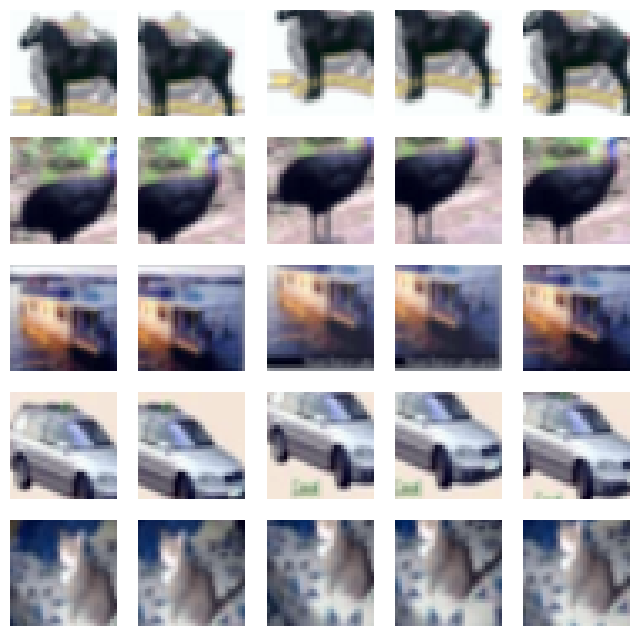

In [20]:
# get some random training images
dataiter = iter(test_loader)
images, labels = next(dataiter)
bs, ncrops, c, h, w = images.size()

images = images.view(-1, c, h, w)

# show images
plot_only_images(images)

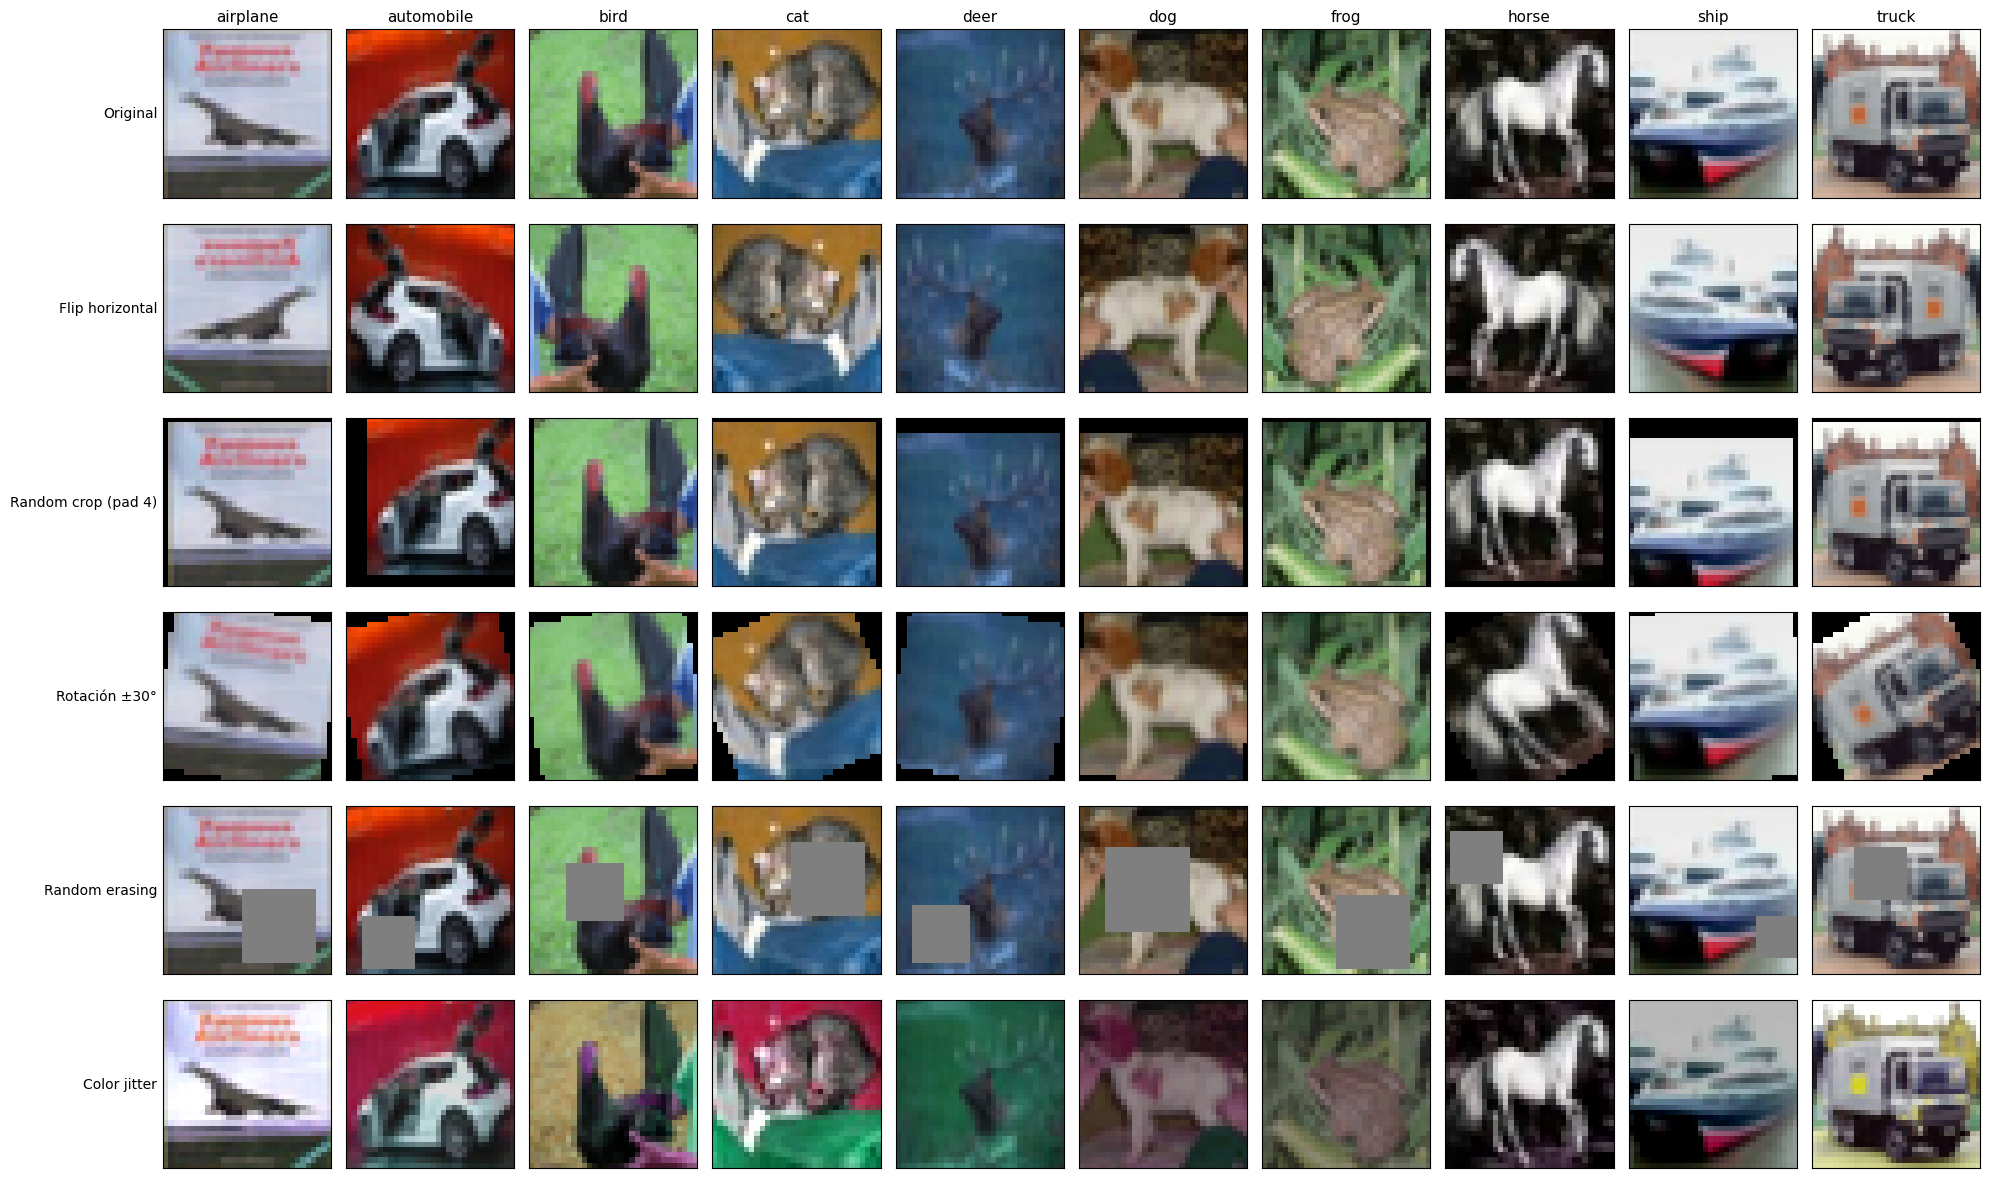

In [21]:
# Dataset sin transformaciones (imágenes PIL originales)
raw = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download=False)
classes = raw.classes

torch.manual_seed(1234)

# Una transformación por fila (sin Normalize, para ver los colores reales)
grid_transforms = {
    'Original': transforms.ToTensor(),
    'Flip horizontal': transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor()]),
    'Random crop (pad 4)': transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.ToTensor()]),
    'Rotación ±30°': transforms.Compose([
        transforms.RandomRotation([-30, 30], interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor()]),
    'Random erasing': transforms.Compose([
        transforms.ToTensor(),
        transforms.RandomErasing(p=1.0, scale=(0.02, 0.25), ratio=(1, 1), value=0.5)]),
    'Color jitter': transforms.Compose([
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.2),
        transforms.ToTensor()]),
}

# Primera imagen de cada clase
first_idx = [raw.targets.index(c) for c in range(len(classes))]

n_rows, n_cols = len(grid_transforms), len(classes)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2*n_cols, 2*n_rows))

for c, idx in enumerate(first_idx):
    pil_img, _ = raw[idx]
    for r, (name, tf) in enumerate(grid_transforms.items()):
        ax = axes[r, c]
        ax.imshow(tf(pil_img).permute(1, 2, 0).clamp(0, 1).numpy())
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(classes[c], fontsize=11)
        if c == 0:
            ax.set_ylabel(name, rotation=0, ha='right', va='center', fontsize=10)

plt.tight_layout()
plt.show()

También podemos ver un igual resultado para los five-crops:

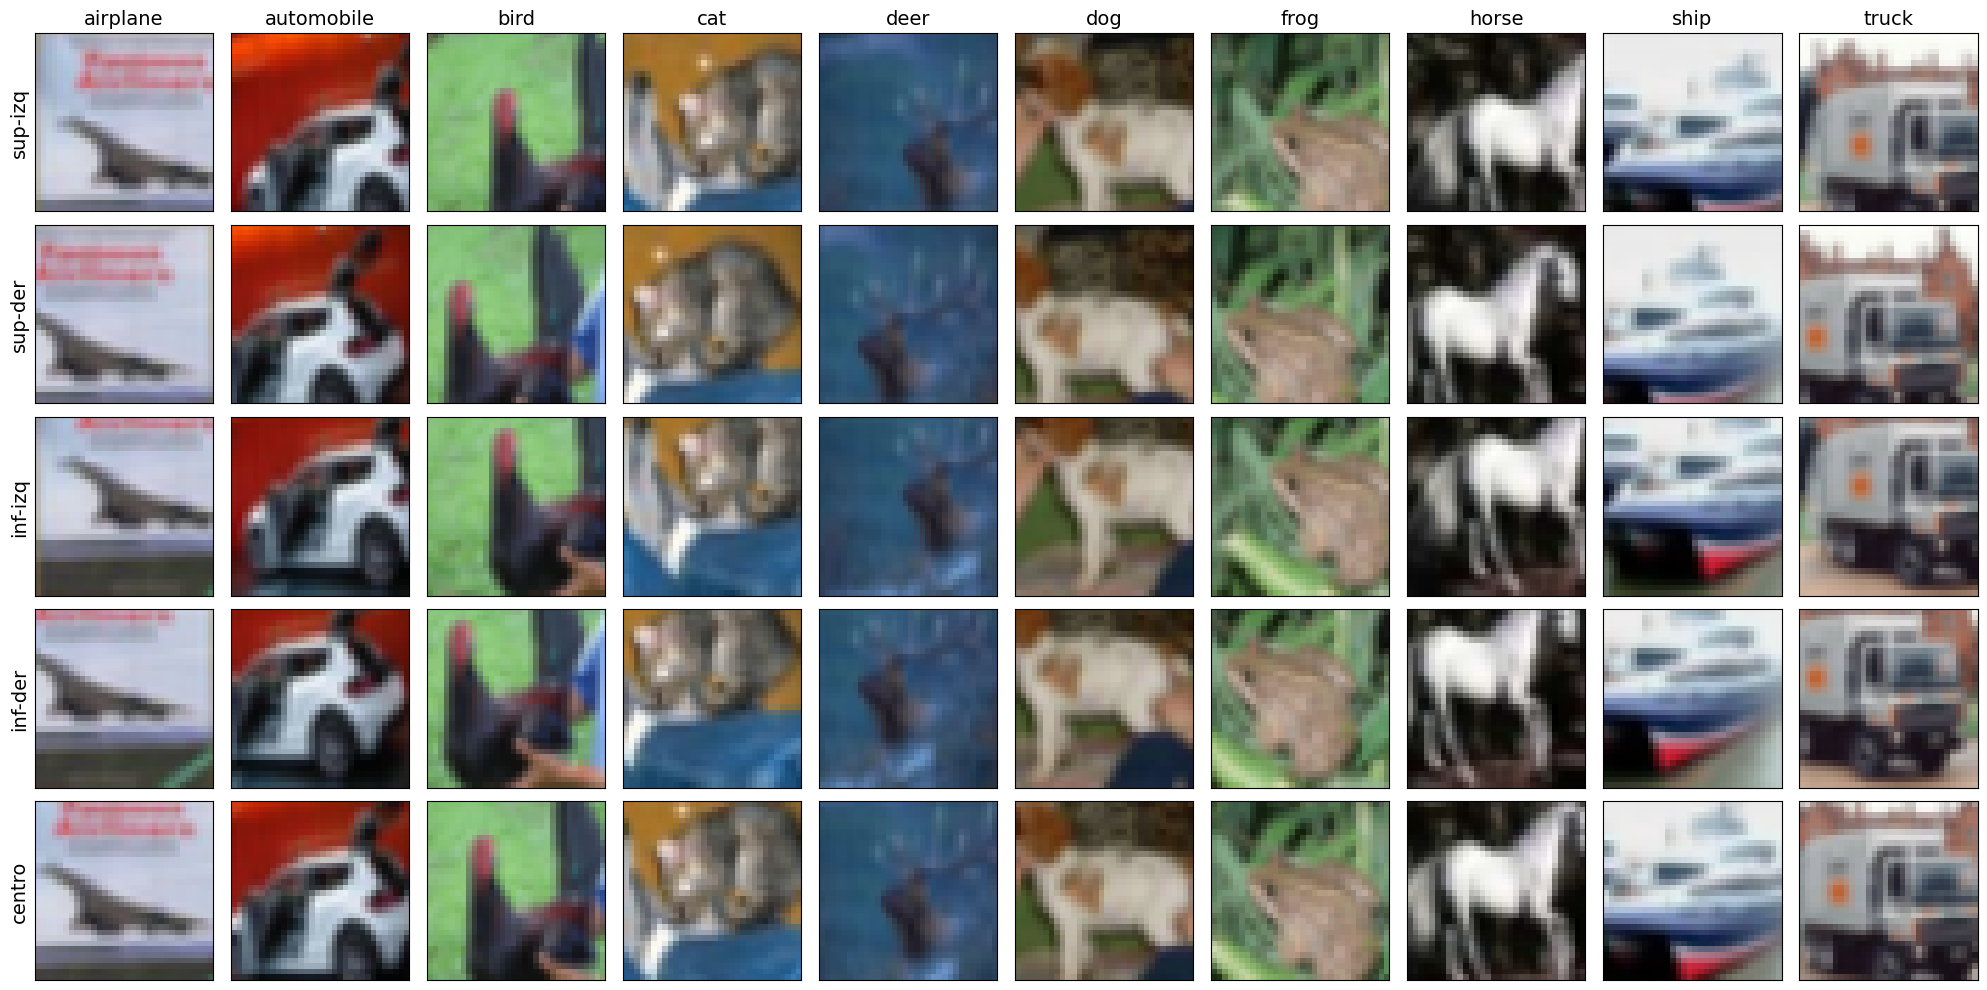

In [22]:
raw = CIFAR10(root="data/CIFAR10/cifar-10-python", train=False, download=False)
idx = [raw.targets.index(c) for c in range(10)]
fc = transforms.Compose([transforms.Resize(40), transforms.FiveCrop(32)])
nombres = ['sup-izq','sup-der','inf-izq','inf-der','centro']
fig, ax = plt.subplots(5, 10, figsize=(20,10))
for c,i in enumerate(idx):
    crops = fc(raw[i][0])
    for r in range(5):
        ax[r,c].imshow(crops[r]); ax[r,c].set_xticks([]); ax[r,c].set_yticks([])
        if r==0: ax[r,c].set_title(raw.classes[c], fontsize=14)
        if c==0: ax[r,c].set_ylabel(nombres[r], fontsize=14)
plt.tight_layout(); plt.show()

The code below saves the notebook and exports it to HTML. To avoid problems, check the result and re-run the saving and exporting sections more than once before completing the lab assignment

In [23]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
# indicate the path to your notebok here
# EXAMPLE: ipynb_file = Path("/content/drive/MyDrive/Colab Notebooks/[UAM-VisDL- NBs]/[UAM-VAAP] Image Data Augmentation (1).ipynb")
# ???
from pathlib import Path

ipynb_file = Path(
    "/content/drive/MyDrive/VISION-ARTIFICIAL/Pr2/[UAM-VAAP]ImageDataAugmentation.ipynb"
)



In [25]:
# @title
from IPython.display import Javascript, display
import time

display(Javascript("""
async function saveNotebook() {
    await google.colab.notebook.saveCheckpoint();
}
saveNotebook();
"""))

time.sleep(10)

<IPython.core.display.Javascript object>

In [26]:
# Export the currently running Google Colab notebook to HTML
# and save it next to the notebook in Google Drive.

from nbconvert import HTMLExporter
import nbformat

html_file = ipynb_file.with_suffix(".html")

with open(ipynb_file, "r", encoding="utf-8") as f:
    notebook = nbformat.read(f, as_version=4)

html_exporter = HTMLExporter()
body, _ = html_exporter.from_notebook_node(notebook)

with open(html_file, "w", encoding="utf-8") as f:
    f.write(body)

print(f"✅ Exported to {html_file}")

✅ Exported to /content/drive/MyDrive/VISION-ARTIFICIAL/Pr2/[UAM-VAAP]ImageDataAugmentation.html
